# Import libraries and configure project

In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Automatically identify project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

DATA_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"
REPORT_DIR = PROJECT_DIR / "reports"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

EVENT_FILE = DATA_DIR / "ehr_event_log_clean.csv"
CASE_FILE = DATA_DIR / "ehr_cases_clean.csv"

print("Project Root:", PROJECT_DIR)
print("Event file:", EVENT_FILE.exists())
print("Case file:", CASE_FILE.exists())

assert EVENT_FILE.exists(), f"Event file missing: {EVENT_FILE}"
assert CASE_FILE.exists(), f"Case file missing: {CASE_FILE}"

print("\nCareFlow Week 3 Environment Ready!")

Project Root: C:\Users\visha\Desktop\CareFlow-Clinical-Pathway-Process-Mining
Event file: True
Case file: True

CareFlow Week 3 Environment Ready!


# Load and validate data

In [12]:
events = pd.read_csv(EVENT_FILE)
cases = pd.read_csv(CASE_FILE)

print("Event Log Shape:", events.shape)
print("Case Data Shape:", cases.shape)

print("\nEvent Log Preview:")
display(events.head())

print("\nCase Data Preview:")
display(cases.head())

assert len(events) == 4875
assert events["case_id"].nunique() == 500
assert events["event_id"].nunique() == 4875

print("\nBase Data Validation: PASSED")

Event Log Shape: (4875, 33)
Case Data Shape: (500, 21)

Event Log Preview:


,case_id,patient_id,age,age_group,sex,region,arrival_mode,acuity,chief_complaint,diagnosis_group,...,location,wait_minutes,duration_minutes,loopback_type,is_loopback,event_status,disposition,data_source,data_version,cleaning_version
0,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Zone-4,0,14,NaN,False,Completed,Discharged Home,Synthetic EHR Simulator,week1-v1,week1-v1
1,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Zone-1,28,2,NaN,True,Completed,Discharged Home,Synthetic EHR Simulator,week1-v1,week1-v1
2,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Zone-4,3,9,NaN,False,Completed,Discharged Home,Synthetic EHR Simulator,week1-v1,week1-v1
3,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Zone-2,9,8,NaN,False,Delayed,Discharged Home,Synthetic EHR Simulator,week1-v1,week1-v1
4,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Zone-1,5,15,NaN,False,Completed,Discharged Home,Synthetic EHR Simulator,week1-v1,week1-v1



Case Data Preview:


,case_id,patient_id,age,age_group,sex,region,arrival_mode,acuity,chief_complaint,diagnosis_group,...,insurance_type,arrival_timestamp,hospital_site,referral_source,disposition,event_count,loopback_type,end_timestamp,length_of_stay_minutes,cleaning_version
0,CF-0000001,PAT-0000001,53,40-64,Male,North,Walk-in,Low,Breathing Difficulty,Gastrointestinal Condition,...,Other,2026-06-28 16:45:08,Site-A,Self,Discharged Home,11,NaN,2026-06-28 20:56:08,251,week1-v1
1,CF-0000002,PAT-0000002,43,40-64,Other/Unknown,South,Referral,High,Dizziness,Migraine,...,Self-Pay,2026-04-30 19:31:53,Site-B,Primary Care,Discharged Home,10,Repeat Doctor Assessment,2026-04-30 23:39:53,248,week1-v1
2,CF-0000003,PAT-0000003,51,40-64,Female,West,Ambulance,Low,Back Pain,Musculoskeletal Pain,...,Other,2026-08-18 18:45:53,Site-C,Other Hospital,Discharged Home,8,Reassessment to Triage,2026-08-18 21:45:53,180,week1-v1
3,CF-0000004,PAT-0000004,9,0-17,Female,North,Ambulance,Critical,Breathing Difficulty,Chest Pain Under Evaluation,...,Public,2026-04-16 18:45:29,Site-C,Emergency Services,Transferred,6,NaN,2026-04-16 20:51:29,126,week1-v1
4,CF-0000005,PAT-0000005,26,18-39,Male,East,Walk-in,Moderate,Allergic Reaction,Chest Pain Under Evaluation,...,Public,2026-08-22 14:21:18,Site-C,Primary Care,Transferred,9,NaN,2026-08-22 17:30:18,189,week1-v1



Base Data Validation: PASSED


# Prepare operational metrics

In [13]:
events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    errors="coerce"
)

events["wait_minutes"] = pd.to_numeric(
    events["wait_minutes"],
    errors="coerce"
)

events["duration_minutes"] = pd.to_numeric(
    events["duration_minutes"],
    errors="coerce"
)

events = events.sort_values(
    ["case_id", "timestamp", "event_sequence"]
).copy()

print("Invalid timestamps:", events["timestamp"].isna().sum())
print("Total events:", len(events))
print("Unique cases:", events["case_id"].nunique())
print("Data preparation completed!")

Invalid timestamps: 0
Total events: 4875
Unique cases: 500
Data preparation completed!


# Operational KPI summary

In [14]:
operational_kpis = pd.DataFrame({
    "Metric": [
        "Total Events",
        "Unique Cases",
        "Average Wait (Minutes)",
        "Median Wait (Minutes)",
        "Maximum Wait (Minutes)",
        "Average Duration (Minutes)",
        "Median Duration (Minutes)",
        "Maximum Duration (Minutes)"
    ],
    "Value": [
        len(events),
        events["case_id"].nunique(),
        events["wait_minutes"].mean(),
        events["wait_minutes"].median(),
        events["wait_minutes"].max(),
        events["duration_minutes"].mean(),
        events["duration_minutes"].median(),
        events["duration_minutes"].max()
    ]
})

display(operational_kpis.round(2))

operational_kpis.to_csv(
    OUTPUT_DIR / "week3_operational_kpis.csv",
    index=False
)

,Metric,Value
0,Total Events,4875.00
1,Unique Cases,500.00
2,Average Wait (Minutes),15.84
3,Median Wait (Minutes),10.00
4,Maximum Wait (Minutes),456.00
5,Average Duration (Minutes),10.62
6,Median Duration (Minutes),9.00
7,Maximum Duration (Minutes),85.00


# Activity-wise waiting time analysis

In [15]:
activity_wait = (
    events.groupby("activity")
    .agg(
        event_count=("event_id", "count"),
        avg_wait=("wait_minutes", "mean"),
        median_wait=("wait_minutes", "median"),
        max_wait=("wait_minutes", "max"),
        avg_duration=("duration_minutes", "mean")
    )
    .reset_index()
    .sort_values("avg_wait", ascending=False)
)

display(activity_wait.round(2))

activity_wait.to_csv(
    OUTPUT_DIR / "week3_activity_wait_analysis.csv",
    index=False
)

,activity,event_count,avg_wait,median_wait,max_wait,avg_duration
0,Admission Decision,66,21.76,12.0,196,12.61
4,Doctor Assessment,574,19.53,12.0,231,10.90
10,Reassessment,79,18.24,12.0,122,8.35
2,Discharge,500,18.02,11.0,126,10.76
6,Imaging Order,196,17.94,12.0,192,10.03
12,Treatment,500,17.76,11.0,456,11.05
3,Discharge Preparation,500,17.67,11.5,198,10.76
9,Lab Sample Collection,373,17.52,11.0,185,10.21
13,Triage,579,17.08,11.0,186,10.47
7,Lab Order,373,16.61,10.0,129,10.72


# Visualize waiting time

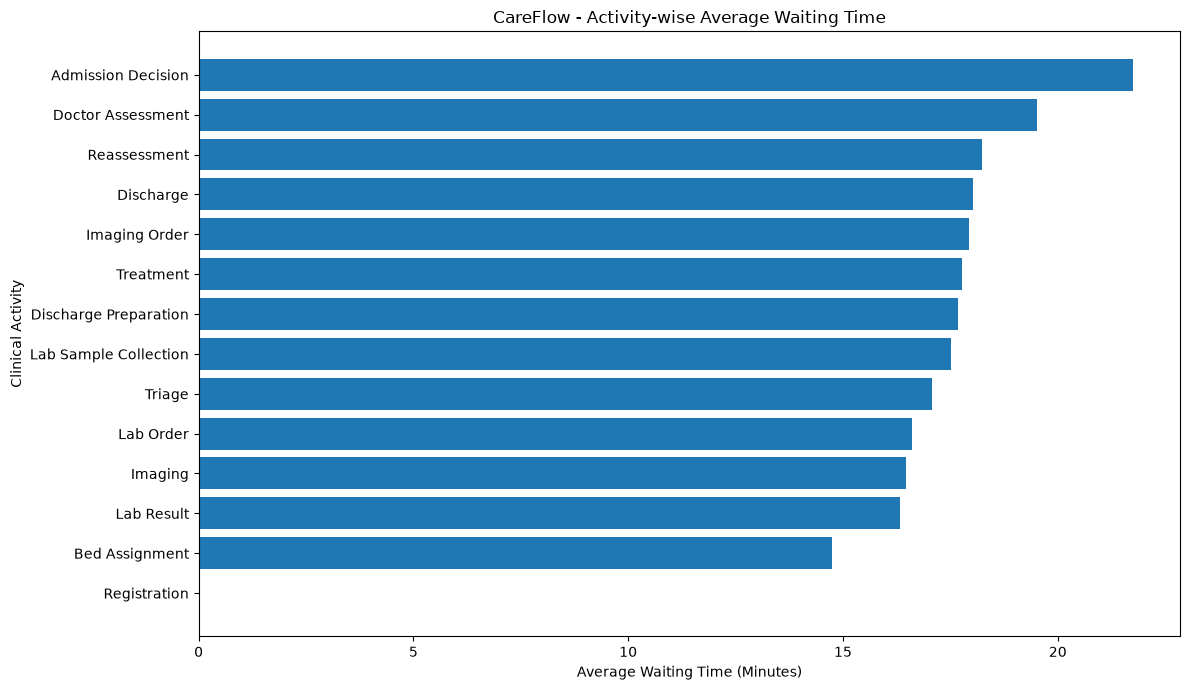

In [16]:
plot_data = activity_wait.sort_values(
    "avg_wait",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["activity"],
    plot_data["avg_wait"]
)

plt.xlabel("Average Waiting Time (Minutes)")
plt.ylabel("Clinical Activity")
plt.title("CareFlow - Activity-wise Average Waiting Time")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "week3_activity_wait_chart.png",
    dpi=300
)

plt.show()

# Resource utilization analysis

In [17]:
resource_analysis = (
    events.groupby("resource_role")
    .agg(
        event_count=("event_id", "count"),
        avg_duration=("duration_minutes", "mean"),
        avg_wait=("wait_minutes", "mean"),
        total_duration=("duration_minutes", "sum")
    )
    .reset_index()
    .sort_values("total_duration", ascending=False)
)

display(resource_analysis.round(2))

resource_analysis.to_csv(
    OUTPUT_DIR / "week3_resource_analysis.csv",
    index=False
)

,resource_role,event_count,avg_duration,avg_wait,total_duration
2,Doctor,1643,10.82,15.94,17778
4,Nurse,1050,10.44,15.87,10961
5,Radiology Technician,586,10.74,16.03,6295
0,Administrator,550,10.65,16.89,5860
3,Lab Technician,518,10.80,14.90,5594
1,Bed Coordinator,528,10.00,15.11,5281


# Activity-wise Bottleneck Prioritization

In [18]:
# Activity-wise bottleneck prioritization

bottleneck_analysis = (
    events.groupby("activity")
    .agg(
        event_count=("event_id", "count"),
        avg_wait=("wait_minutes", "mean"),
        median_wait=("wait_minutes", "median"),
        p90_wait=("wait_minutes", lambda x: x.quantile(0.90)),
        max_wait=("wait_minutes", "max"),
        total_wait=("wait_minutes", "sum"),
        avg_duration=("duration_minutes", "mean")
    )
    .reset_index()
)

total_wait = bottleneck_analysis["total_wait"].sum()

bottleneck_analysis["wait_contribution_pct"] = (
    bottleneck_analysis["total_wait"] / total_wait * 100
)

bottleneck_analysis = bottleneck_analysis.sort_values(
    "total_wait",
    ascending=False
)

display(bottleneck_analysis.round(2))

,activity,event_count,avg_wait,median_wait,p90_wait,max_wait,total_wait,avg_duration,wait_contribution_pct
4,Doctor Assessment,574,19.53,12.0,41.0,231,11209,10.90,14.51
13,Triage,579,17.08,11.0,38.4,186,9891,10.47,12.81
2,Discharge,500,18.02,11.0,42.0,126,9008,10.76,11.66
12,Treatment,500,17.76,11.0,35.0,456,8882,11.05,11.50
3,Discharge Preparation,500,17.67,11.5,42.0,198,8834,10.76,11.44
9,Lab Sample Collection,373,17.52,11.0,39.0,185,6535,10.21,8.46
7,Lab Order,373,16.61,10.0,35.8,129,6194,10.72,8.02
8,Lab Result,373,16.33,11.0,35.0,213,6090,9.92,7.88
6,Imaging Order,196,17.94,12.0,33.5,192,3516,10.03,4.55
5,Imaging,196,16.47,11.0,33.0,147,3228,11.45,4.18


# Case-Level Waiting Time Analysis

In [19]:
# Case-Level Waiting Time Analysis

case_wait_analysis = (
    events.groupby("case_id")
    .agg(
        patient_id=("patient_id", "first"),
        event_count=("event_id", "count"),
        total_wait=("wait_minutes", "sum"),
        avg_wait=("wait_minutes", "mean"),
        max_wait=("wait_minutes", "max"),
        total_duration=("duration_minutes", "sum"),
        disposition=("disposition", "first")
    )
    .reset_index()
)

case_wait_analysis = case_wait_analysis.sort_values(
    "total_wait",
    ascending=False
)

display(case_wait_analysis.head(20).round(2))

,case_id,patient_id,event_count,total_wait,avg_wait,max_wait,total_duration,disposition
401,CF-0000402,PAT-0000402,9,523,58.11,456,103,Discharged Home
260,CF-0000261,PAT-0000261,11,422,38.36,225,136,Discharged Home
178,CF-0000179,PAT-0000179,12,408,34.00,114,122,Discharged Home
150,CF-0000151,PAT-0000151,9,384,42.67,104,118,Discharged Home
282,CF-0000283,PAT-0000283,14,377,26.93,213,134,Admitted
262,CF-0000263,PAT-0000263,11,355,32.27,108,142,Discharged Home
122,CF-0000123,PAT-0000123,13,352,27.08,126,146,Discharged Home
55,CF-0000056,PAT-0000056,12,344,28.67,152,112,Left Before Completion
193,CF-0000194,PAT-0000194,11,344,31.27,110,70,Discharged Home
293,CF-0000294,PAT-0000294,9,339,37.67,218,81,Discharged Home


In [20]:
# Identify cases with extreme waiting time

print("Total Cases:", len(case_wait_analysis))

print(
    "Cases with total waiting above 120 minutes:",
    (case_wait_analysis["total_wait"] > 120).sum()
)

print(
    "Cases with maximum activity wait above 60 minutes:",
    (case_wait_analysis["max_wait"] > 60).sum()
)

print("\nTop 10 cases by maximum waiting time:")

display(
    case_wait_analysis.nlargest(10, "max_wait")
)

Total Cases: 500
Cases with total waiting above 120 minutes: 330
Cases with maximum activity wait above 60 minutes: 144

Top 10 cases by maximum waiting time:


,case_id,patient_id,event_count,total_wait,avg_wait,max_wait,total_duration,disposition
401,CF-0000402,PAT-0000402,9,523,58.111111,456,103,Discharged Home
208,CF-0000209,PAT-0000209,6,312,52.000000,231,82,Left Before Completion
260,CF-0000261,PAT-0000261,11,422,38.363636,225,136,Discharged Home
461,CF-0000462,PAT-0000462,9,328,36.444444,223,86,Discharged Home
293,CF-0000294,PAT-0000294,9,339,37.666667,218,81,Discharged Home
282,CF-0000283,PAT-0000283,14,377,26.928571,213,134,Admitted
309,CF-0000310,PAT-0000310,9,280,31.111111,198,86,Discharged Home
164,CF-0000165,PAT-0000165,10,305,30.500000,196,138,Admitted
490,CF-0000491,PAT-0000491,8,262,32.750000,192,44,Discharged Home
157,CF-0000158,PAT-0000158,13,320,24.615385,186,169,Admitted


# High-Wait Case Activity Investigation

In [21]:
# Investigate activities responsible for high waiting time

priority_cases = [
    "CF-0000402",
    "CF-0000209",
    "CF-0000261",
    "CF-0000462",
    "CF-0000294",
    "CF-0000283"
]

case_activity_analysis = (
    events[
        events["case_id"].isin(priority_cases)
    ]
    .sort_values(
        ["case_id", "wait_minutes"],
        ascending=[True, False]
    )
    [[
        "case_id",
        "activity",
        "timestamp",
        "wait_minutes",
        "duration_minutes",
        "resource_role",
        "department",
        "event_status",
        "disposition"
    ]]
)

display(case_activity_analysis)

,case_id,activity,timestamp,wait_minutes,duration_minutes,resource_role,department,event_status,disposition
2060,CF-0000209,Doctor Assessment,2026-01-19 00:43:47,231,4,Nurse,Emergency,Completed,Left Before Completion
2059,CF-0000209,Triage,2026-01-18 20:40:47,52,12,Doctor,Emergency,Completed,Left Before Completion
2062,CF-0000209,Discharge Preparation,2026-01-19 01:21:47,17,32,Nurse,Emergency,Reworked,Left Before Completion
2061,CF-0000209,Treatment,2026-01-19 00:53:47,6,11,Doctor,Emergency,Completed,Left Before Completion
2063,CF-0000209,Discharge,2026-01-19 01:59:47,6,16,Doctor,Emergency,Completed,Left Before Completion
2058,CF-0000209,Registration,2026-01-18 19:41:47,0,7,Doctor,Emergency,Completed,Left Before Completion
2559,CF-0000261,Doctor Assessment,2026-01-20 03:29:01,225,17,Nurse,Emergency,Completed,Discharged Home
2562,CF-0000261,Lab Result,2026-01-20 05:36:01,56,23,Nurse,Laboratory,Completed,Discharged Home
2558,CF-0000261,Triage,2026-01-19 23:35:01,31,9,Doctor,Emergency,Completed,Discharged Home
2563,CF-0000261,Imaging Order,2026-01-20 06:23:01,24,3,Nurse,Emergency,Delayed,Discharged Home


In [22]:
# Highest waiting activity for each priority case

worst_activity_per_case = (
    case_activity_analysis
    .groupby("case_id")
    .head(1)
    .sort_values("wait_minutes", ascending=False)
)

display(worst_activity_per_case)

,case_id,activity,timestamp,wait_minutes,duration_minutes,resource_role,department,event_status,disposition
3947,CF-0000402,Treatment,2026-08-22 18:53:11,456,14,Bed Coordinator,Emergency,Reworked,Discharged Home
2060,CF-0000209,Doctor Assessment,2026-01-19 00:43:47,231,4,Nurse,Emergency,Completed,Left Before Completion
2559,CF-0000261,Doctor Assessment,2026-01-20 03:29:01,225,17,Nurse,Emergency,Completed,Discharged Home
4511,CF-0000462,Treatment,2026-05-08 02:29:00,223,19,Doctor,Emergency,Delayed,Discharged Home
2902,CF-0000294,Doctor Assessment,2026-08-21 09:16:31,218,2,Lab Technician,Emergency,Completed,Discharged Home
2792,CF-0000283,Lab Result,2026-04-02 02:14:34,213,9,Lab Technician,Laboratory,Completed,Admitted


# Priority Case Clinical Pathway Analysis

In [23]:
# Complete clinical pathway for priority cases

priority_cases = [
    "CF-0000402",
    "CF-0000209",
    "CF-0000261",
    "CF-0000462",
    "CF-0000294",
    "CF-0000283"
]

priority_pathways = (
    events[
        events["case_id"].isin(priority_cases)
    ]
    .sort_values(
        ["case_id", "timestamp", "event_sequence"]
    )
    [[
        "case_id",
        "event_sequence",
        "previous_activity",
        "activity",
        "timestamp",
        "wait_minutes",
        "duration_minutes",
        "resource_role",
        "department",
        "event_status",
        "disposition"
    ]]
)

display(priority_pathways)

,case_id,event_sequence,previous_activity,activity,timestamp,wait_minutes,duration_minutes,resource_role,department,event_status,disposition
2058,CF-0000209,1,NaN,Registration,2026-01-18 19:41:47,0,7,Doctor,Emergency,Completed,Left Before Completion
2059,CF-0000209,2,Registration,Triage,2026-01-18 20:40:47,52,12,Doctor,Emergency,Completed,Left Before Completion
2060,CF-0000209,3,Triage,Doctor Assessment,2026-01-19 00:43:47,231,4,Nurse,Emergency,Completed,Left Before Completion
2061,CF-0000209,4,Doctor Assessment,Treatment,2026-01-19 00:53:47,6,11,Doctor,Emergency,Completed,Left Before Completion
2062,CF-0000209,5,Treatment,Discharge Preparation,2026-01-19 01:21:47,17,32,Nurse,Emergency,Reworked,Left Before Completion
2063,CF-0000209,6,Discharge Preparation,Discharge,2026-01-19 01:59:47,6,16,Doctor,Emergency,Completed,Left Before Completion
2557,CF-0000261,1,NaN,Registration,2026-01-19 22:49:01,0,15,Bed Coordinator,Emergency,Reworked,Discharged Home
2558,CF-0000261,2,Registration,Triage,2026-01-19 23:35:01,31,9,Doctor,Emergency,Completed,Discharged Home
2559,CF-0000261,3,Triage,Doctor Assessment,2026-01-20 03:29:01,225,17,Nurse,Emergency,Completed,Discharged Home
2560,CF-0000261,4,Doctor Assessment,Lab Order,2026-01-20 04:02:01,16,5,Doctor,Emergency,Completed,Discharged Home


# Activity and resource investigation

In [24]:
# Aggregate waiting time by activity and resource

priority_resource_analysis = (
    events[
        events["case_id"].isin(priority_cases)
    ]
    .groupby(["activity", "resource_role", "department"])
    .agg(
        event_count=("event_id", "count"),
        avg_wait=("wait_minutes", "mean"),
        max_wait=("wait_minutes", "max"),
        total_wait=("wait_minutes", "sum")
    )
    .reset_index()
    .sort_values("total_wait", ascending=False)
)

display(priority_resource_analysis.round(2))

,activity,resource_role,department,event_count,avg_wait,max_wait,total_wait
9,Doctor Assessment,Nurse,Emergency,3,153.33,231,460
31,Treatment,Bed Coordinator,Emergency,1,456.00,456,456
8,Doctor Assessment,Lab Technician,Emergency,3,82.33,218,247
32,Treatment,Doctor,Emergency,2,114.50,223,229
20,Lab Result,Lab Technician,Laboratory,1,213.00,213,213
35,Triage,Doctor,Emergency,5,22.00,52,110
21,Lab Result,Nurse,Laboratory,2,32.00,56,64
3,Discharge,Doctor,Emergency,5,11.20,22,56
4,Discharge Preparation,Administrator,Emergency,3,18.00,22,54
5,Discharge Preparation,Doctor,Emergency,2,22.00,37,44


# Resource Activity Mapping Validation

In [25]:
# Resource-Activity Mapping Validation

resource_activity_check = (
    events.groupby(
        ["activity", "resource_role", "department"]
    )
    .agg(
        event_count=("event_id", "count"),
        avg_wait=("wait_minutes", "mean"),
        max_wait=("wait_minutes", "max")
    )
    .reset_index()
    .sort_values(
        ["activity", "event_count"],
        ascending=[True, False]
    )
)

display(resource_activity_check.round(2))

,activity,resource_role,department,event_count,avg_wait,max_wait
2,Admission Decision,Doctor,Emergency,24,16.83,59
0,Admission Decision,Administrator,Emergency,12,36.83,196
4,Admission Decision,Nurse,Emergency,9,20.89,79
1,Admission Decision,Bed Coordinator,Emergency,7,25.43,67
3,Admission Decision,Lab Technician,Emergency,7,14.14,36
...,...,...,...,...,...,...
82,Triage,Nurse,Emergency,113,17.49,186
78,Triage,Administrator,Emergency,72,15.60,72
83,Triage,Radiology Technician,Emergency,68,16.43,119
81,Triage,Lab Technician,Emergency,58,15.09,52


# Identify unusual assignments

In [26]:
# Review activities performed by multiple resource roles

role_variation = (
    events.groupby("activity")
    .agg(
        resource_count=("resource_role", "nunique"),
        resource_roles=(
            "resource_role",
            lambda x: ", ".join(sorted(x.dropna().unique()))
        ),
        total_events=("event_id", "count")
    )
    .reset_index()
    .sort_values("resource_count", ascending=False)
)

display(role_variation)

,activity,resource_count,resource_roles,total_events
0,Admission Decision,6,"Administrator, Bed Coordinator, Doctor, Lab Te...",66
1,Bed Assignment,6,"Administrator, Bed Coordinator, Doctor, Lab Te...",66
2,Discharge,6,"Administrator, Bed Coordinator, Doctor, Lab Te...",500
3,Discharge Preparation,6,"Administrator, Bed Coordinator, Doctor, Lab Te...",500
4,Doctor Assessment,6,"Administrator, Bed Coordinator, Doctor, Lab Te...",574
5,Imaging,6,"Administrator, Bed Coordinator, Doctor, Lab Te...",196
6,Imaging Order,6,"Administrator, Bed Coordinator, Doctor, Lab Te...",196
7,Lab Order,6,"Administrator, Bed Coordinator, Doctor, Lab Te...",373
8,Lab Result,6,"Administrator, Bed Coordinator, Doctor, Lab Te...",373
9,Lab Sample Collection,6,"Administrator, Bed Coordinator, Doctor, Lab Te...",373


# Validate incomplete pathway cases

In [27]:
# Check incomplete cases and their actual event sequences

incomplete_cases = events[
    events["disposition"] == "Left Before Completion"
]

incomplete_summary = (
    incomplete_cases.groupby("case_id")
    .agg(
        event_count=("event_id", "count"),
        activities=("activity", lambda x: " -> ".join(x)),
        last_activity=("activity", "last")
    )
    .reset_index()
)

display(incomplete_summary)

,case_id,event_count,activities,last_activity
0,CF-0000026,9,Registration -> Triage -> Doctor Assessment ->...,Discharge
1,CF-0000056,12,Registration -> Triage -> Doctor Assessment ->...,Discharge
2,CF-0000103,9,Registration -> Triage -> Doctor Assessment ->...,Discharge
3,CF-0000113,8,Registration -> Triage -> Doctor Assessment ->...,Discharge
4,CF-0000133,6,Registration -> Triage -> Doctor Assessment ->...,Discharge
5,CF-0000209,6,Registration -> Triage -> Doctor Assessment ->...,Discharge
6,CF-0000221,9,Registration -> Triage -> Doctor Assessment ->...,Discharge
7,CF-0000299,8,Registration -> Triage -> Doctor Assessment ->...,Discharge
8,CF-0000308,9,Registration -> Triage -> Doctor Assessment ->...,Discharge
9,CF-0000341,9,Registration -> Triage -> Doctor Assessment ->...,Discharge


# Correct Incomplete Pathway Validation

In [28]:
# Sort events chronologically before case analysis

events_sorted = events.sort_values(
    ["case_id", "timestamp", "event_sequence"]
).copy()

# Extract one row per case
case_summary = (
    events_sorted.groupby("case_id")
    .agg(
        event_count=("event_id", "count"),
        activities=("activity", lambda x: " -> ".join(x)),
        last_activity=("activity", "last"),
        disposition=("disposition", "last"),
        final_timestamp=("timestamp", "max")
    )
    .reset_index()
)

# Identify incomplete cases
incomplete_summary = case_summary[
    case_summary["disposition"] == "Left Before Completion"
]

display(incomplete_summary)

,case_id,event_count,activities,last_activity,disposition,final_timestamp
25,CF-0000026,9,Registration -> Triage -> Doctor Assessment ->...,Discharge,Left Before Completion,2026-06-04 13:59:14
55,CF-0000056,12,Registration -> Triage -> Doctor Assessment ->...,Discharge,Left Before Completion,2026-05-02 12:07:49
102,CF-0000103,9,Registration -> Triage -> Doctor Assessment ->...,Discharge,Left Before Completion,2026-06-03 20:28:27
112,CF-0000113,8,Registration -> Triage -> Doctor Assessment ->...,Discharge,Left Before Completion,2026-05-24 09:26:17
132,CF-0000133,6,Registration -> Triage -> Doctor Assessment ->...,Discharge,Left Before Completion,2026-09-11 04:21:10
208,CF-0000209,6,Registration -> Triage -> Doctor Assessment ->...,Discharge,Left Before Completion,2026-01-19 01:59:47
220,CF-0000221,9,Registration -> Triage -> Doctor Assessment ->...,Discharge,Left Before Completion,2026-07-30 12:43:55
298,CF-0000299,8,Registration -> Triage -> Doctor Assessment ->...,Discharge,Left Before Completion,2026-04-09 04:17:35
307,CF-0000308,9,Registration -> Triage -> Doctor Assessment ->...,Discharge,Left Before Completion,2026-04-29 02:34:19
340,CF-0000341,9,Registration -> Triage -> Doctor Assessment ->...,Discharge,Left Before Completion,2026-06-01 04:18:07


# Check Disposition vs Last Activity

In [29]:
# Check disposition and final activity combinations

disposition_validation = (
    case_summary.groupby(
        ["disposition", "last_activity"]
    )
    .size()
    .reset_index(name="case_count")
    .sort_values("case_count", ascending=False)
)

display(disposition_validation)

,disposition,last_activity,case_count
1,Discharged Home,Discharge,380
0,Admitted,Discharge,66
3,Transferred,Discharge,38
2,Left Before Completion,Discharge,16


# Inspect all 16 cases

In [30]:
# Inspect all incomplete cases at event level

incomplete_case_ids = incomplete_summary["case_id"].tolist()

incomplete_events = (
    events_sorted[
        events_sorted["case_id"].isin(incomplete_case_ids)
    ]
    .sort_values(["case_id", "timestamp", "event_sequence"])
)

display(
    incomplete_events[
        [
            "case_id",
            "event_sequence",
            "activity",
            "timestamp",
            "event_status",
            "disposition"
        ]
    ].to_string(index=False)
)

'   case_id  event_sequence              activity           timestamp event_status            disposition\nCF-0000026               1          Registration 2026-06-04 10:56:14    Completed Left Before Completion\nCF-0000026               2                Triage 2026-06-04 11:41:14    Completed Left Before Completion\nCF-0000026               3     Doctor Assessment 2026-06-04 12:01:14    Completed Left Before Completion\nCF-0000026               4             Lab Order 2026-06-04 12:22:14    Completed Left Before Completion\nCF-0000026               5 Lab Sample Collection 2026-06-04 12:40:14    Completed Left Before Completion\nCF-0000026               6            Lab Result 2026-06-04 12:49:14    Completed Left Before Completion\nCF-0000026               7             Treatment 2026-06-04 13:33:14      Delayed Left Before Completion\nCF-0000026               8 Discharge Preparation 2026-06-04 13:55:14    Completed Left Before Completion\nCF-0000026               9             Discha

# Check final event consistency

In [31]:
# Compare final activity and disposition

final_events = (
    events_sorted.groupby("case_id")
    .tail(1)
)

display(
    final_events[
        final_events["disposition"] == "Left Before Completion"
    ][
        [
            "case_id",
            "activity",
            "event_status",
            "disposition",
            "timestamp"
        ]
    ]
)

,case_id,activity,event_status,disposition,timestamp
246,CF-0000026,Discharge,Completed,Left Before Completion,2026-06-04 13:59:14
527,CF-0000056,Discharge,Completed,Left Before Completion,2026-05-02 12:07:49
1000,CF-0000103,Discharge,Completed,Left Before Completion,2026-06-03 20:28:27
1091,CF-0000113,Discharge,Completed,Left Before Completion,2026-05-24 09:26:17
1282,CF-0000133,Discharge,Delayed,Left Before Completion,2026-09-11 04:21:10
2063,CF-0000209,Discharge,Completed,Left Before Completion,2026-01-19 01:59:47
2178,CF-0000221,Discharge,Completed,Left Before Completion,2026-07-30 12:43:55
2961,CF-0000299,Discharge,Completed,Left Before Completion,2026-04-09 04:17:35
3043,CF-0000308,Discharge,Completed,Left Before Completion,2026-04-29 02:34:19
3359,CF-0000341,Discharge,Completed,Left Before Completion,2026-06-01 04:18:07


In [32]:
# Case-level final activity validation

final_events = (
    events_sorted
    .sort_values(["case_id", "timestamp", "event_sequence"])
    .groupby("case_id")
    .tail(1)
)

disposition_validation = (
    final_events
    .groupby(["disposition", "activity"])
    .size()
    .reset_index(name="case_count")
    .sort_values("case_count", ascending=False)
)

display(disposition_validation)

,disposition,activity,case_count
1,Discharged Home,Discharge,380
0,Admitted,Discharge,66
3,Transferred,Discharge,38
2,Left Before Completion,Discharge,16
